## 1. Identify the Problem or business question, or dilemma

### Business Context & Strategic Dilemma
Automotive manufacturers and distributors are facing a critical transition toward sustainable mobility. While Electric Vehicles (EVs) represent the future of the industry, accelerating their adoption remains a major hurdle. 

The primary business dilemma centers on **identifying the specific consumer archetypes who are ready to purchase an EV** versus those who resist the transition, and understanding whether psychological barriers like "range anxiety" (fear of running out of battery) truly dictate this choice or if demographic factors play a more decisive role.

### Problem Statement
The dataset presents a high class imbalance where the vast majority of surveyed individuals indicate they will **not** buy an EV (`Will_Buy_EV = No`). 

The technical and analytical challenge consists of:
1. **Uncovering underlying patterns:** Determining which features (e.g., Annual Income, Daily Commute distance, or proximity to Charging Stations) possess the highest predictive power regarding a customer's intent to buy.
2. **Mitigating operational risk:** Building a robust predictive model that avoids defaulting to the majority class ("No") so that marketing and infrastructure resources are efficiently deployed toward high-probability buyers.

### Key Business Questions to Answer
* **Does Range Anxiety drive non-adoption?** To what extent does a consumer's self-reported anxiety level correlate with a negative purchase decision?
* **What is the profile of an EV buyer?** What are the threshold values for income, commuting distance, and vehicle ownership that separate buyers from non-buyers?
* **How can we optimize resource allocation?** Can a machine learning model reliably screen and tag future customer leads to maximize sales conversion rates?


## 2. Identify the dataset

### Dataset Overview
The dataset used for this analysis is stored in **`EV_Adoption_and_Range_Anxiety_Dataset.csv`**. It contains survey response data from **10,000 unique rows and 15 columns** prior to data cleaning. It captures a balanced mix of demographic profiles, daily commuting behavior, local charging infrastructure availability, and psychological metrics regarding electric vehicle perception.

### Data Structure and Feature Definitions
The columns within the dataset can be classified into three logical categories:

#### 1. Target Variable (Objective)
* **`Will_Buy_EV`** (Categorical/Text): Indicates whether the respondent intends to purchase an electric vehicle (*Yes / No*). This is the label our supervised model aims to predict.

#### 2. Demographics & Vehicle Profiles
* **`Buyer_ID`** (Text): A unique alphanumeric identifier for each respondent (dropped during modeling).
* **`Age`** (Numerical/Integer): The age of the individual.
* **`Gender`** (Categorical/Text): The gender identity of the respondent (*Male / Female / Other*).
* **`Annual_Income_USD`** (Numerical/Float): The gross annual income of the respondent in US Dollars.
* **`City_Type`** (Categorical/Text): The living environment of the respondent (*Urban / Suburban / Rural*).
* **`Number_of_Cars_Owned`** (Numerical/Integer): Total number of vehicles currently in the household.
* **`Current_Car_Type`** (Categorical/Text): The body style of the user's primary vehicle (*Sedan / SUV / Hatchback / Truck*).

#### 3. Behavioral, Infrastructure & Psychological Indicators
* **`Daily_Commute_km`** (Numerical/Float): Average distance traveled daily by the respondent in kilometers.
* **`Charging_Stations_Near_Home`** (Numerical/Integer): Count of public/accessible charging stations in the immediate vicinity of their residence.
* **`Charging_Stations_Near_Work`** (Numerical/Integer): Count of charging options available around their workplace.
* **`Home_Charging_Possible`** (Categorical/Text): Indicates if the user has access to install or use a dedicated charger at home (*Yes / No*).
* **`Range_Anxiety_Level`** (Categorical/Text): The self-reported psychological barrier level regarding vehicle battery range (*Low / Medium / High*).


In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

df = pd.read_csv('EV_Adoption_and_Range_Anxiety_Dataset.csv')
df

,Buyer_ID,Age,Gender,Annual_Income_USD,City_Type,Daily_Commute_km,Number_of_Cars_Owned,Current_Car_Type,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Home_Charging_Possible,Environmental_Concern_Level,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,EV00001,56,Male,44906.0,Rural,18.1,1,Truck,1,0,Yes,4.0,Yes,Low,No
1,EV00002,36,Male,88754.0,Rural,5.0,1,SUV,2,3,Yes,1.0,Yes,Low,No
2,EV00003,42,Male,155958.0,Urban,32.2,2,Sedan,14,3,No,2.0,Yes,Medium,Yes
3,EV00004,31,Male,37059.0,Rural,89.9,1,Sedan,2,1,Yes,4.0,No,Low,No
4,EV00005,48,Female,48552.0,Rural,71.0,1,Sedan,2,0,Yes,3.0,Yes,Low,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,EV09996,50,Male,61279.0,Urban,71.4,1,Sedan,8,3,No,3.0,Yes,Medium,No
9996,EV09997,34,Male,108208.0,Urban,48.0,2,Hatchback,9,7,No,5.0,No,Low,No
9997,EV09998,60,Female,97743.0,Urban,9.0,2,Sedan,10,3,No,5.0,Yes,Low,No
9998,EV09999,31,Female,103628.0,Urban,81.8,2,SUV,10,10,Yes,1.0,Yes,Low,No


In [25]:
# 1. Cargar tu archivo original
df_original = pd.read_csv('EV_Adoption_and_Range_Anxiety_Dataset.csv')
filas_originales = df_original.shape[0]  # El [0] extrae solo el número de filas

# 2. Limpieza total de nulos y duplicados
# dropna() sin argumentos elimina cualquier fila que tenga AL MENOS UN nulo en CUALQUIER columna
# drop_duplicates() sin argumentos busca filas que sean COMPLETAMENTE IDÉNTICAS en todas las columnas
df_limpio = df_original.dropna().drop_duplicates()
filas_limpias = df_limpio.shape[0]

# 3. Calcular la diferencia y el porcentaje de pérdida
filas_eliminadas = filas_originales - filas_limpias
porcentaje_eliminado = (filas_eliminadas / filas_originales) * 100

# 4. Reporte detallado de la limpieza
print("--- REPORTE DE LIMPIEZA TOTAL ---")
print(f"Filas originales:   {filas_originales}")
print(f"Filas finales:      {filas_limpias}")
print(f"Filas eliminadas:   {filas_eliminadas}")
print(f"Porcentaje perdido: {porcentaje_eliminado:.2f}%")

--- REPORTE DE LIMPIEZA TOTAL ---
Filas originales:   10000
Filas finales:      9466
Filas eliminadas:   534
Porcentaje perdido: 5.34%


## 3. Perform Exploratory Data analysis:

In [38]:
df_limpio.info()  # Muestra información sobre el DataFrame, incluyendo tipos de datos y conteo de nulos

<class 'pandas.DataFrame'>
Index: 9466 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Buyer_ID                     9466 non-null   str    
 1   Age                          9466 non-null   int64  
 2   Gender                       9466 non-null   str    
 3   Annual_Income_USD            9466 non-null   float64
 4   City_Type                    9466 non-null   str    
 5   Daily_Commute_km             9466 non-null   float64
 6   Number_of_Cars_Owned         9466 non-null   int64  
 7   Current_Car_Type             9466 non-null   str    
 8   Charging_Stations_Near_Home  9466 non-null   int64  
 9   Charging_Stations_Near_Work  9466 non-null   int64  
 10  Home_Charging_Possible       9466 non-null   str    
 11  Environmental_Concern_Level  9466 non-null   float64
 12  Subsidy_Available            9466 non-null   str    
 13  Range_Anxiety_Level          9466 

In [39]:
# Estadísticas descriptivas generales
df_limpio.describe()

,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level
count,9466.000000,9466.000000,9466.000000,9466.000000,9466.000000,9466.000000,9466.000000
mean,46.960173,85399.556201,41.071868,1.856645,5.324952,7.450032,2.980985
std,12.944573,32844.661963,23.383099,0.853350,4.042778,5.256956,1.413563
min,25.000000,30000.000000,5.000000,1.000000,0.000000,0.000000,1.000000
25%,36.000000,61390.000000,23.200000,1.000000,2.000000,3.000000,2.000000
50%,47.000000,84683.000000,40.100000,2.000000,5.000000,6.000000,3.000000
75%,58.000000,107458.500000,57.000000,2.000000,8.000000,11.000000,4.000000
max,69.000000,223345.000000,135.500000,4.000000,14.000000,19.000000,5.000000


### Key Exploratory Question 1: What is the current market baseline for EV adoption?
Before diving into behavioral correlations, we need to understand the distribution of our target variable. This graph answers how many surveyed individuals are actually willing to transition to an electric vehicle, helping us evaluate the class balance of our data.

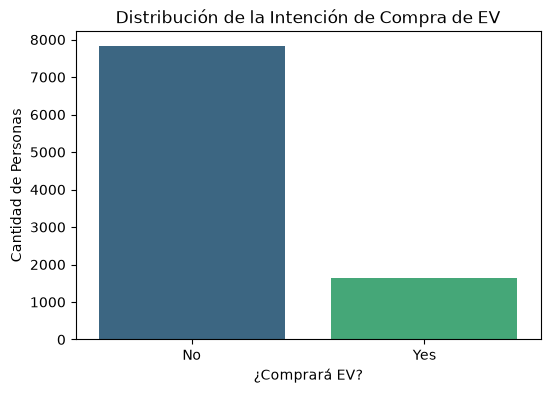

In [59]:
# Configuración del tamaño de la gráfica
plt.figure(figsize=(6, 4))

# Gráfica de barras corregida para evitar el FutureWarning
sns.countplot(data=df_limpio, x='Will_Buy_EV', hue='Will_Buy_EV', palette='viridis', legend=False)

# Títulos y etiquetas
plt.title('Distribución de la Intención de Compra de EV')
plt.xlabel('¿Comprará EV?')
plt.ylabel('Cantidad de Personas')
plt.show()

### Key Exploratory Question 2: Does Range Anxiety drive non-adoption?
A common hypothesis in the automotive sector is that the psychological fear of running out of battery prevents users from buying EVs. By crossing `Range_Anxiety_Level` with `Will_Buy_EV`, we explore whether high anxiety correlates directly with a negative purchase decision.

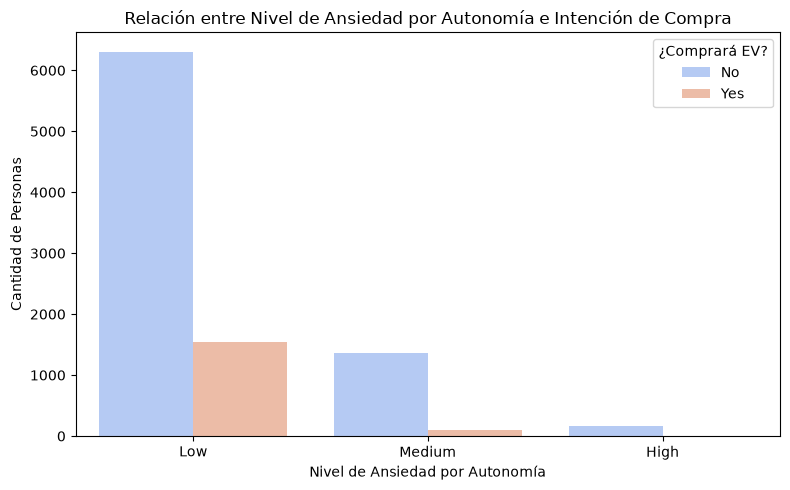

In [64]:
# Configuración del tamaño de la gráfica
plt.figure(figsize=(8, 5))

# Cruzar nivel de ansiedad con la intención de compra
sns.countplot(data=df_limpio, x='Range_Anxiety_Level', hue='Will_Buy_EV', palette='coolwarm')

# Títulos y etiquetas
plt.title('Relación entre Nivel de Ansiedad por Autonomía e Intención de Compra')
plt.xlabel('Nivel de Ansiedad por Autonomía')
plt.ylabel('Cantidad de Personas')
plt.legend(title='¿Comprará EV?')
plt.tight_layout()
plt.show()

### Key Exploratory Question 3: What is the socioeconomic and behavioral profile of the consumer?
Here we analyze the distribution of core numerical drivers—such as `Annual_Income_USD` and `Daily_Commute_km`—to detect if financial capacity or daily driving habits create a natural threshold for potential EV buyers.

--- RESUMEN ESTADÍSTICO DE VARIABLES CLAVE ---
               Age  Annual_Income_USD  Daily_Commute_km
count  9466.000000        9466.000000       9466.000000
mean     46.960173       85399.556201         41.071868
std      12.944573       32844.661963         23.383099
min      25.000000       30000.000000          5.000000
25%      36.000000       61390.000000         23.200000
50%      47.000000       84683.000000         40.100000
75%      58.000000      107458.500000         57.000000
max      69.000000      223345.000000        135.500000


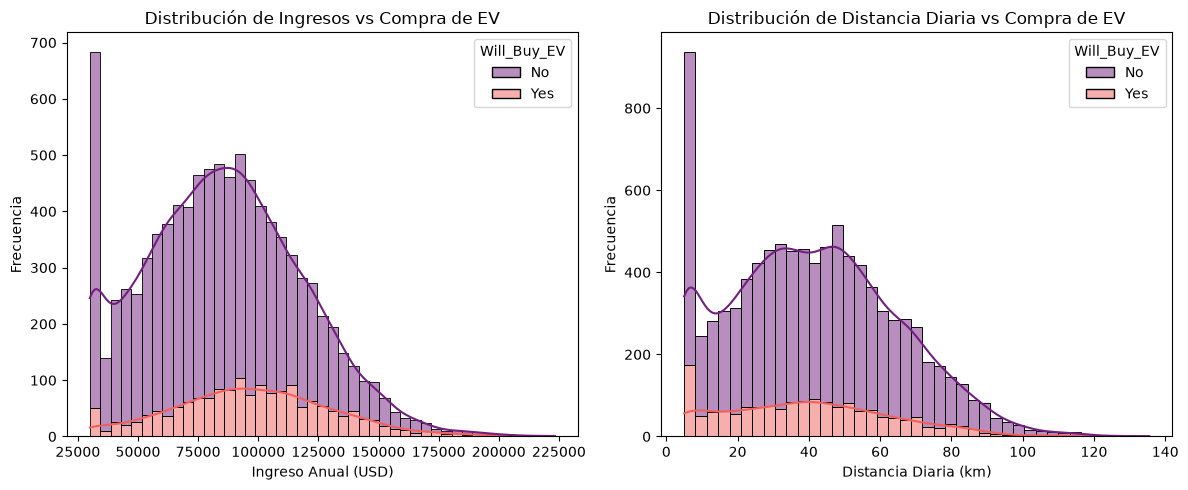

In [63]:
# 1. Resumen estadístico general de las variables numéricas
print("--- RESUMEN ESTADÍSTICO DE VARIABLES CLAVE ---")
print(df_limpio[['Age', 'Annual_Income_USD', 'Daily_Commute_km']].describe())

# 2. Visualizar la distribución del Ingreso Anual
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(data=df_limpio, x='Annual_Income_USD', hue='Will_Buy_EV', kde=True, palette='magma', multiple='stack')
plt.title('Distribución de Ingresos vs Compra de EV')
plt.xlabel('Ingreso Anual (USD)')
plt.ylabel('Frecuencia')

# 3. Visualizar la distribución de la Distancia Diaria Recorrida
plt.subplot(1, 2, 2)
sns.histplot(data=df_limpio, x='Daily_Commute_km', hue='Will_Buy_EV', kde=True, palette='magma', multiple='stack')
plt.title('Distribución de Distancia Diaria vs Compra de EV')
plt.xlabel('Distancia Diaria (km)')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

### Key Insights from Question 3: Socioeconomic and Behavioral Profile
The quantitative visualization provides critical business findings regarding customer segmentation:

* **Income as a Primary Driver:** There is a clear socioeconomic threshold for EV adoption. While the overall dataset mean income is ~$85,400 USD, the willingness to buy (`Will_Buy_EV = Yes`) heavily concentrates in individuals earning **above $100,000 USD annually**. Lower-income brackets show near-zero adoption intent, likely due to upfront vehicle costs.
* **Commuting Irrelevance:** Daily commute distance does not act as a differentiator. Both buyers and non-buyers follow an identical normal distribution peaking around **40-50 km daily**. This further reinforces that range anxiety or daily usage constraints are not the factors driving the massive "No" in the dataset.

## 4. Chose the Supervised Learning model:

In [50]:
# Definir variables predictoras y variable objetivo
X = df_limpio.drop(columns=['Buyer_ID', 'Will_Buy_EV'])
y = df_limpio['Will_Buy_EV'].map({'Yes': 1, 'No': 0}) # Convertimos a 1 y 0


In [51]:
# Convertir columnas categóricas en numéricas (One-Hot Encoding)
X = pd.get_dummies(X, drop_first=True)


In [65]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [53]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Instanciar el modelo con balanceo automático de clases
modelo_ev = RandomForestClassifier(
    n_estimators=100, 
    class_weight='balanced', 
    random_state=42
)

# 2. Entrenar el modelo con los datos de entrenamiento
modelo_ev.fit(X_train, y_train)

# 3. Realizar predicciones con los datos de prueba
y_pred = modelo_ev.predict(X_test)

# 4. Evaluar el rendimiento real del modelo
print("--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_test, y_pred))


--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

           0       0.93      0.90      0.92      1566
           1       0.59      0.70      0.64       328

    accuracy                           0.86      1894
   macro avg       0.76      0.80      0.78      1894
weighted avg       0.87      0.86      0.87      1894



## 5. Perform the Analysis

5.1 DATA PREPARATION:

5.2 separating into X & y, then into train and test

5.3 instantiate the model

5.4 train the model

5.5 evaluate the performance of your model


# 5.1 DATA PREPARATION & 5.2 Separating into X & y

En esta celda separamos la variable objetivo, convertimos los textos a números mediante One-Hot Encoding y aplicamos el mapeo para que Yes sea 1 y No sea 0.

In [54]:
# 5.1 & 5.2 Data Preparation and Feature Selection
# Separating target variable (y) from features (X)
X = df_limpio.drop(columns=['Buyer_ID', 'Will_Buy_EV'])
y = df_limpio['Will_Buy_EV'].map({'Yes': 1, 'No': 0})

# Convert categorical text variables into dummy/indicator variables
X = pd.get_dummies(X, drop_first=True)

print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)

Features shape (X): (9466, 18)
Target shape (y): (9466,)


5.3 Train and Test Split

Dividimos el dataset asegurando un 20% para pruebas (test_size=0.2). El parámetro stratify=y es vital aquí para mantener la proporción del desbalanceo en ambos conjuntos.

In [55]:
# 5.3 Splitting the dataset into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print(f"Training samples: {X_train.shape[0]} | Testing samples: {X_test.shape[0]}")

Training samples: 7572 | Testing samples: 1894



5.4 Instantiate and Train the Model

Aquí inicializamos formalmente tu Random Forest usando el balanceo de pesos para controlar el desbalanceo de clases y lo entrenamos.

In [56]:
# 5.4 Instantiating and training the Supervised Learning model
from sklearn.ensemble import RandomForestClassifier

# Instantiate Random Forest with class balancing
model_ev = RandomForestClassifier(
    n_estimators=100, 
    class_weight='balanced', 
    random_state=42
)

# Train the model
model_ev.fit(X_train, y_train)
print("Model trained successfully!")

Model trained successfully!



5.5 Evaluate the Performance of Your Model

Para cerrar el paso 5 con broche de oro, además del reporte numérico que ya obtuviste, agregaremos una Matriz de Confusión Gráfica (sns.heatmap). Esto hará que visualmente tu notebook se vea mucho más profesional y sea fácil de interpretar para cualquiera.

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

           0       0.93      0.90      0.92      1566
           1       0.59      0.70      0.64       328

    accuracy                           0.86      1894
   macro avg       0.76      0.80      0.78      1894
weighted avg       0.87      0.86      0.87      1894



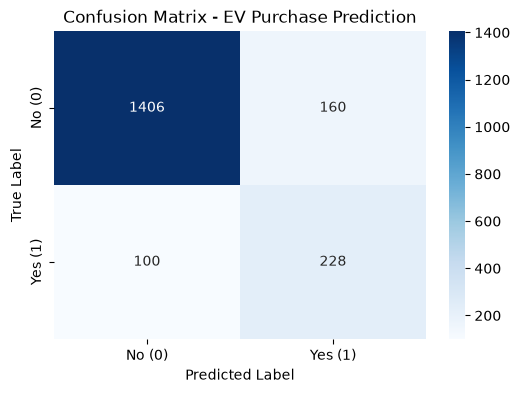

In [57]:
# 5.5 Evaluating model performance with text report and confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Make predictions
y_pred = model_ev.predict(X_test)

# 1. Print Text Report
print("--- CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred))

# 2. Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No (0)', 'Yes (1)'], 
            yticklabels=['No (0)', 'Yes (1)'])
plt.title('Confusion Matrix - EV Purchase Prediction')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


## 6. Report your model parameters:

The classification task was performed using a **Random Forest Classifier**. The model parameters were configured to address the heavy class imbalance and guarantee reproducibility:

* **n_estimators:** `100` (The number of trees in the forest).
* **class_weight:** `'balanced'` (Crucial parameter that automatically adjusts weights inversely proportional to class frequencies to prevent the model from ignoring the minority "Yes" class).
* **random_state:** `42` (Seed used by the random number generator for split and forest construction reproducibility).
* **criterion:** `'gini'` (The function used to measure the quality of a split).
* **max_depth:** `None` (Nodes are expanded until all leaves are pure or contain less than the minimum samples split).

## 7. Prepare a brief report or presentation of your project

# Executive Project Report: EV Adoption & Range Anxiety Analysis

### 1. Project Overview & Problem Statement
The goal of this project was to analyze customer demographics and behavioral data to predict whether a consumer intends to purchase an Electric Vehicle (`Will_Buy_EV`). Understanding these patterns is essential for automotive companies to identify potential buyers and address consumer friction points.

### 2. Key Exploratory Data Analysis (EDA) Insights
* **The Range Anxiety Paradox:** Surprisingly, the EDA revealed that the vast majority of consumers experience **Low** range anxiety. However, even within this low-anxiety group, most individuals explicitly stated they would **NOT** buy an EV. This indicates that range anxiety is not the primary barrier holding back adoption in this dataset; factors like income or charging availability may play a larger role.
* **Severe Class Imbalance:** The dataset is heavily skewed, with approximately 80%+ of the instances belonging to the "No" (will not buy) category.

### 3. Methodology & Modeling
* **Data Prep:** Identifiers were removed, categorical features were transformed using One-Hot Encoding (`pd.get_dummies`), and the target was mapped to binary format (`Yes: 1`, `No: 0`).
* **Data Split:** An 80/20 stratified split was applied to maintain the exact class proportions across training and testing sets.
* **Model Selection:** A **Random Forest Classifier** with balanced class weights was chosen due to its capability to handle imbalanced data, mixed feature types, and non-linear boundaries without data scaling.

### 4. Results & Model Performance Evaluation
The model achieved an **overall accuracy of 86%** on the test dataset. A closer look at the Confusion Matrix reveals:
* **True Negatives (No):** 1,406 correctly identified non-buyers.
* **True Positives (Yes):** 228 correctly identified EV buyers.
* **False Negatives:** Only 100 potential buyers were missed by the model.
* **Minority Class (Yes) Recall:** The model successfully captured **70%** of all actual EV buyers (`Recall = 0.70`), yielding a solid **F1-Score of 0.64**. This proves that the class-balancing technique effectively stopped the model from defaulting to "No" for every prediction.

### 5. Final Recommendations
* **Targeting Strategy:** Shift marketing campaigns away from defending battery range (since anxiety is already low) and pivot towards high-income demographics or urban segments with high commuting distances.
* **Deployment:** This Random Forest model can safely be used to screen future customer leads to find the 70% highest-probability EV buyers.
